# Linear probing over GPT-1 layers on 4 tasks

We want to do linear probing over all the layers of GPT-1 to see the capability of separating linearly concepts such as positiveness.

We use frozen GPT-1 Pretrained state. 
Datasets : SST-2 (sentiment), CoLA (gramamtical correctness) TREC (6 classes) and AG News (articles, 4 classes).

In [ ]:
from pathlib import Path
from datasets import load_dataset
import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, OpenAIGPTModel
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [72]:
SEED = 42
DEVICE = "mps"
N_TRAIN = 5000
BATCH_SIZE = 32
MAX_LENGTH = 128
POOLING_METHOD = "mean_pooling"  # "last_token" or "mean_pooling"

TASKS = {
    "sst2": {
        "dataset_id": "stanfordnlp/sst2",
        "config": None,
        "text_column": "sentence",
        "label_column": "label",
        "eval_split": "validation",
        "name": "SST-2",
        "task": "sentiment",
        "show_baseline": False,
    },
    "cola": {
        "dataset_id": "nyu-mll/glue",
        "config": "cola",
        "text_column": "sentence",
        "label_column": "label",
        "eval_split": "validation",
        "name": "CoLA",
        "task": "grammatical acceptability",
        "show_baseline": True,
    },
    "trec": {
        "dataset_id": "SetFit/TREC-QC",
        "config": None,
        "text_column": "text",
        "label_column": "label_coarse",
        "eval_split": "test",
        "name": "TREC",
        "task": "question classification",
        "show_baseline": True,
    },
    "ag_news": {
        "dataset_id": "fancyzhx/ag_news",
        "config": None,
        "text_column": "text",
        "label_column": "label",
        "eval_split": "test",
        "name": "AG News",
        "task": "topic classification",
        "show_baseline": True,
    },
}

loading datasets

In [63]:
datasets = {}
for task_id, task in TASKS.items():
    dataset = load_dataset(task["dataset_id"], name=task["config"])
    dataset = dataset.select_columns([task["text_column"], task["label_column"]])
    column_names = {
        source: target
        for source, target in [
            (task["text_column"], "sentence"),
            (task["label_column"], "label"),
        ]
        if source != target
    }
    if column_names:
        dataset = dataset.rename_columns(column_names)

    datasets[task_id] = {
        "train": dataset["train"].shuffle(seed=SEED).select(range(N_TRAIN)),
        "eval": dataset[task["eval_split"]],
    }
    print(f"{task['name']} — train: {len(datasets[task_id]['train'])}, "
          f"eval ({task['eval_split']}): {len(datasets[task_id]['eval'])}")
    print("example:", datasets[task_id]["train"][0])

SST-2 — train: 5000, eval (validation): 872
example: {'sentence': 'klein , charming in comedies like american pie and dead-on in election , ', 'label': 1}
CoLA — train: 5000, eval (validation): 1043
example: {'sentence': 'Sodium is a little too peppy for me to want to try mixing and water in a teacup.', 'label': 0}


Repo card metadata block was not found. Setting CardData to empty.


TREC — train: 5000, eval (test): 500
example: {'sentence': 'How can I transport files from one computer to another ?', 'label': 0}
AG News — train: 5000, eval (test): 7600
example: {'sentence': 'Bangladesh paralysed by strikes Opposition activists have brought many towns and cities in Bangladesh to a halt, the day after 18 people died in explosions at a political rally.', 'label': 0}


load GPT-1 (frozen weights) 

In [64]:
model_id = "openai-community/openai-gpt"

tokenizer = AutoTokenizer.from_pretrained(model_id)
model = OpenAIGPTModel.from_pretrained(model_id)
model.to(DEVICE)
model.requires_grad_(False)
model.eval()

tokenizer.padding_side = "right"
tokenizer.pad_token = tokenizer.unk_token
print("device:", DEVICE)
print("embedding dim:", model.config.n_embd)
print("nb representations:", model.config.n_layer + 1)

Loading weights: 100%|██████████| 146/146 [00:00<00:00, 15656.79it/s]
[transformers] OpenAIGPTModel LOAD REPORT from: openai-community/openai-gpt
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


device: mps
embedding dim: 768
nb representations: 13


extract embeddings : 

2 methods 
- last_token 
- mean_pooling

In [65]:
@torch.inference_mode()
def extract_embeddings(data, batch_size=32, max_length=128, method="last_token"):
    """
    method:
        "last_token": take the last non-padding token at each layer.
        "mean_pooling": average the non-padding tokens at each layer.
    """
    if method not in {"last_token", "mean_pooling"}:
        raise ValueError("please use method 'last_token' or 'mean_pooling'")

    embeddings = [[] for _ in range(model.config.n_layer + 1)]
    for start in range(0, len(data), batch_size):
        sentences = data[start:start + batch_size]["sentence"]
        inputs = tokenizer(
            sentences, padding=True, truncation=True,
            max_length=max_length, return_tensors="pt",
        )
        inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

        # Forward pass: all layers are returned by the same call.
        outputs = model(**inputs, output_hidden_states=True, return_dict=True)
        mask = inputs["attention_mask"]
        last_positions = mask.sum(dim=1) - 1
        rows = torch.arange(len(sentences), device=DEVICE)
        pooling_mask = mask.unsqueeze(-1)

        for layer, h in enumerate(outputs.hidden_states):
            # h: (batch_size, sequence_length, hidden_dim)
            if method == "last_token":
                vectors = h[rows, last_positions]
            else:
                layer_mask = pooling_mask.to(dtype=h.dtype)
                vectors = (h * layer_mask).sum(dim=1) / layer_mask.sum(dim=1).clamp_min(1)

            embeddings[layer].append(vectors.cpu())

    X = [torch.cat(batches, dim=0).numpy() for batches in embeddings]
    y = np.asarray(data["label"])
    return X, y

fit logistic regression on each dataset, for every layer embedding

In [66]:
def fit_probes(X_train, y_train, X_eval, y_eval):
    probes = []
    accuracies = []

    for layer in range(len(X_train)):
        probe = make_pipeline(
            StandardScaler(),
            LogisticRegression(C=1.0, max_iter=2000),
        )
        probe.fit(X_train[layer], y_train)
        accuracy = probe.score(X_eval[layer], y_eval)
        probes.append(probe)
        accuracies.append(accuracy)
        print(f"Couche {layer:02d} : {accuracy:.2%}")

    return probes, accuracies


def plot_accuracies(accuracies, title, baseline=None, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 4))

    ax.plot(range(len(accuracies)), accuracies, marker="o", label="linear classification acc")
    if baseline is not None:
        ax.axhline(baseline, color="gray", linestyle="--", label="majority baseline")
    ax.set_xticks(range(len(accuracies)))
    ax.set_xlabel("layers")
    ax.set_ylabel("accuracy")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()
    return ax

In [73]:
results = {}

for task_id, task in TASKS.items():
    print(f"\n{task['name']} — {task['task']}", flush=True)
    print("Extracting train embeddings...", flush=True)
    X_train, y_train = extract_embeddings(
        datasets[task_id]["train"], batch_size=BATCH_SIZE,
        max_length=MAX_LENGTH, method=POOLING_METHOD,
    )
    print("Extracting eval embeddings...", flush=True)
    X_eval, y_eval = extract_embeddings(
        datasets[task_id]["eval"], batch_size=BATCH_SIZE,
        max_length=MAX_LENGTH, method=POOLING_METHOD,
    )
    print("nb representations:", len(X_train))
    print("representation shape:", X_train[0].shape)

    probes, accuracies = fit_probes(X_train, y_train, X_eval, y_eval)

    # Always predict the most frequent label in this training subset.
    classes, counts = np.unique(y_train, return_counts=True)
    majority_label = classes[np.argmax(counts)]
    baseline = float(np.mean(y_eval == majority_label))
    results[task_id] = {
        "probes": probes,
        "accuracies": accuracies,
        "baseline": baseline,
        "n_train": len(y_train),
        "n_eval": len(y_eval),
    }
    del X_train, X_eval, y_train, y_eval


SST-2 — sentiment
Extracting train embeddings...
Extracting eval embeddings...
nb representations: 13
representation shape: (5000, 768)
Couche 00 : 76.49%
Couche 01 : 75.34%
Couche 02 : 75.11%
Couche 03 : 75.92%
Couche 04 : 77.06%
Couche 05 : 78.10%
Couche 06 : 80.05%
Couche 07 : 80.62%
Couche 08 : 81.54%
Couche 09 : 81.08%
Couche 10 : 80.28%
Couche 11 : 80.05%
Couche 12 : 79.59%

CoLA — grammatical acceptability
Extracting train embeddings...
Extracting eval embeddings...
nb representations: 13
representation shape: (5000, 768)
Couche 00 : 66.16%
Couche 01 : 66.25%
Couche 02 : 66.83%
Couche 03 : 67.21%
Couche 04 : 65.48%
Couche 05 : 65.87%
Couche 06 : 69.61%
Couche 07 : 70.76%
Couche 08 : 73.44%
Couche 09 : 72.20%
Couche 10 : 71.81%
Couche 11 : 71.52%
Couche 12 : 70.66%

TREC — question classification
Extracting train embeddings...
Extracting eval embeddings...
nb representations: 13
representation shape: (5000, 768)
Couche 00 : 78.60%
Couche 01 : 72.20%
Couche 02 : 81.00%
Couche 03 

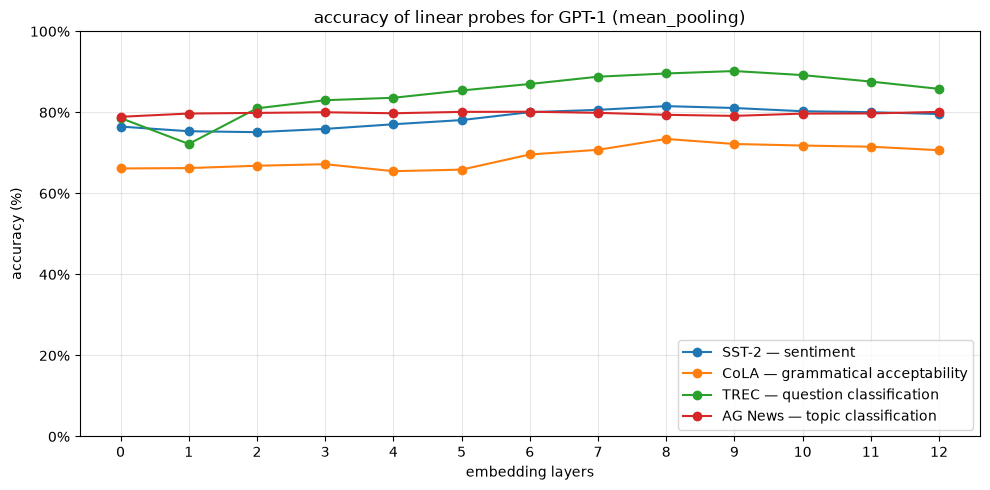

In [74]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(10, 5))

for task_id, task in TASKS.items():
    accuracies = results[task_id]["accuracies"]
    ax.plot(
        range(len(accuracies)),
        accuracies,
        marker="o",
        label=f"{task['name']} — {task['task']}",
    )

ax.set_xticks(range(model.config.n_layer + 1))
ax.set_xlabel("embedding layers")
ax.set_ylabel("accuracy (%)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_ylim(0, 1)
ax.set_title(f"accuracy of linear probes for GPT-1 ({POOLING_METHOD})")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")

fig.tight_layout()
plt.show()

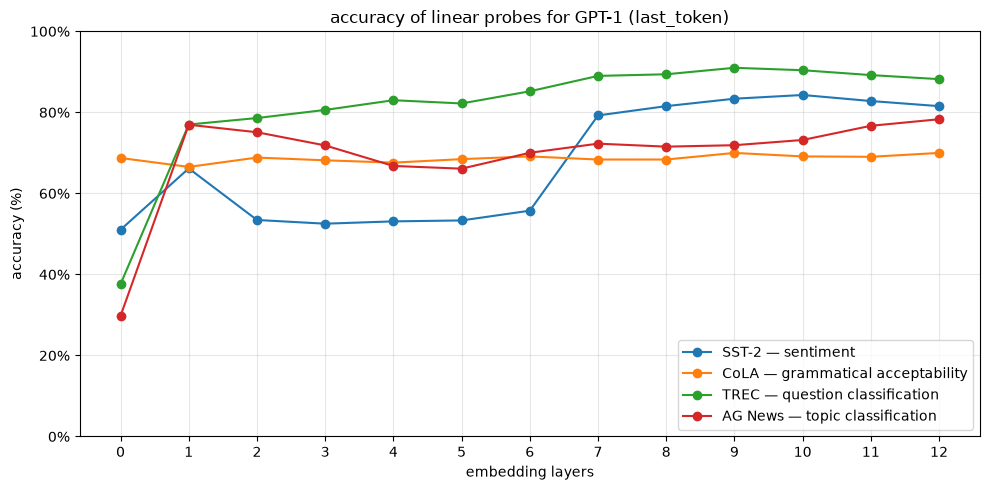

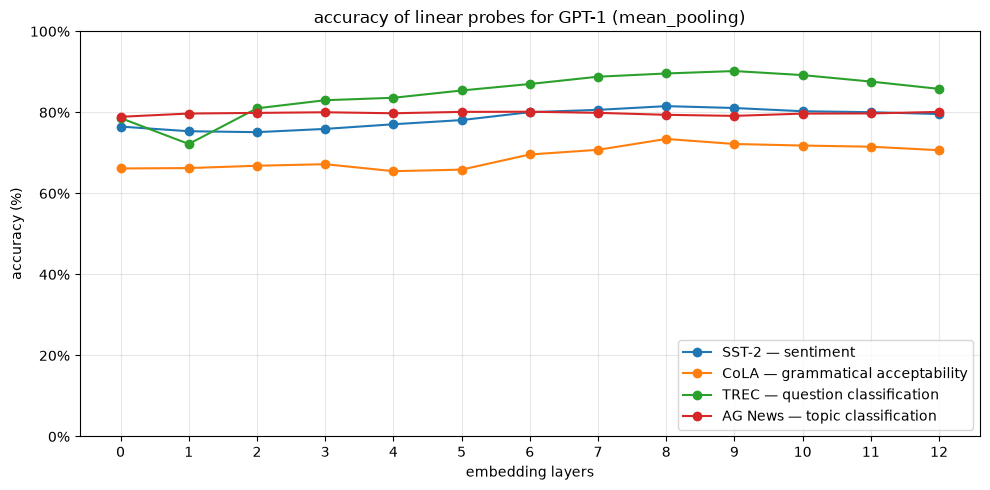

Analysis and remarks : 

1) last_token 

We observe that accuracy is increasing on all task along the layers, but stabilize quite quickly.  
What's happening is that at layer 0, the model only see the embedding of last token without any context, so it is impossible to have information. Then the attention mecanism allows the model to capture interactions between other words of the sentence/paragraph. Therefore, the model can adapt his embeddings and modelize the concept ! The jump between layers 6-7 for SST2 dataset is quite surprising (it is not variance, it does the same for other seeds). Is the concept harder to understand ? Is there really something special learned in those layers ? 

2) mean_pooling 

It's different than last_token because we already have the whole prompt information at layer 0 (even if information can be squashed). 

<b>We clearly see that the gain is marginal along the layers. Maybe I was too confident about GPT-1 pretrained abilities and I should've fine-tuned the model before for each task ?</b>


3) other remark (afterwards)

CoLA curve makes no sense : accuracy is not the right metric to look at (we should compute matthews correlation instead)